<a href="https://colab.research.google.com/github/priyanujgoswami09275-dotcom/numpy-sales-report---engine/blob/main/Sales.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Original sales shape: (11, 5, 12)
Number of dimensions: 3
Total number of sales values: 660
Total sales per store shape: (11, 12)
Monthly targets: [30000.         33636.36363636 37272.72727273 40909.09090909
 44545.45454545 48181.81818182 51818.18181818 55454.54545455
 59090.90909091 62727.27272727 66363.63636364 70000.        ]
[[[False  True False  True  True  True  True False False  True False
   False]
  [False  True False False  True  True False  True  True  True False
    True]
  [ True  True  True False False False  True  True False False False
   False]
  [ True False  True  True  True  True  True False  True False False
   False]
  [ True  True  True  True False  True  True False False False False
   False]]

 [[ True False  True False False  True  True  True False False  True
   False]
  [ True  True  True False False False False  True False  True  True
    True]
  [ True False  True  True  True False  True  True False False False
   False]
  [ True  True  True  True  True Fa

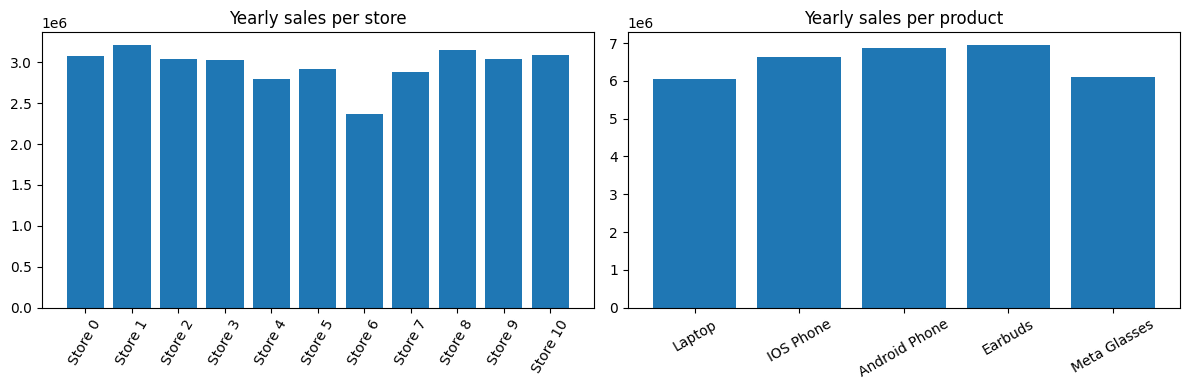

In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

np.random.seed(11)

months = np.arange(1, 13)
month_names = np.array(["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"])
stores = np.array([f"Store {i}" for i in range(11)])
products = np.array(["Laptop","IOS Phone","Android Phone","Earbuds","Meta Glasses"])
sales = np.random.randint(1000,100001, (11,5,12))

print("Original sales shape:", sales.shape)
print("Number of dimensions:", sales.ndim)
print("Total number of sales values:", sales.size)

total_sales_per_store = sales.sum(axis=1)
print("Total sales per store shape:", total_sales_per_store.shape)

q1 = sales[:, :, 0:3]
q2 = sales[:, :, 3:6]
q3 = sales[:, :, 6:9]
q4 = sales[:, :, 9:12]
store5_laptop = sales[5, 0, :]
store2_q2 = sales[2, :, 3:6]
last_cell = sales[-1, -1, -1]



target = np.linspace(30000 , 70000, 12)
print("Monthly targets:", target)
beat=sales>target
print(beat)

high = sales > 90000
low = sales < 10000
extreme = high | low
print(extreme)

missed = ~beat
print(missed)

store_totals = sales.sum(axis=(1, 2))
product_totals = sales.sum(axis=(0, 2))
month_totals = sales.sum(axis=(0, 1))

print("Annual sales per store:", store_totals)
print("Annual sales per product:", product_totals)
print("Total sales per month:", month_totals)

average_store_sales = store_totals.mean()
below_average = store_totals < average_store_sales

print("Average annual sales per store:", average_store_sales)
print("Stores below average:", stores[below_average])


glasses_q4 = beat[:, 4, 9:].all(axis=1)

print("Stores that beat the Meta Glasses target "
      "in all of Q4:", stores[glasses_q4])


picked_store_indices = [1, 4, 7]
picked = sales[picked_store_indices]

print("Selected stores' sales shape:", picked.shape)

best3 = np.argsort(month_totals)[-3:][::-1]

print("Best 3 months:", month_names[best3])

picked_best = sales[picked_store_indices][:, :, best3]

print("Selected stores in best 3 months shape:",
      picked_best.shape)

print("Months beating target, per product (out of 132):")
print(pd.Series(beat.sum(axis=(0, 2)), index=products))


print("Monthly total vs target:")
print(pd.DataFrame({"Total": month_totals,
                    "Target (55 store-products)": (target * 55).astype(int)},
                   index=month_names))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].bar(stores, store_totals)
ax[0].set_title("Yearly sales per store")
ax[0].tick_params(axis="x", rotation=60)
ax[1].bar(products, product_totals)
ax[1].set_title("Yearly sales per product")
ax[1].tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.show()









